# Process ICI Cohorts

This notebook processes bulk RNA-seq and clinical data for three ICI (immune checkpoint inhibitor) cohorts:
- **Hugo** (SKCM, anti-PD1/Pembrolizumab, GSE78220)
- **Riaz** (SKCM, anti-PD1/Nivolumab, GSE91061)
- **Rose** (BLCA, multiple ICI agents, GSE176307)

For each cohort we:
1. Load raw TPM expression and clinical data
2. Map sample IDs to patient IDs
3. Convert Entrez gene IDs → gene symbols (Hugo/Riaz)
4. Filter to pre-treatment samples only
5. Build a raw AnnData object with clinical metadata in `.obs`
6. Filter low-expression genes (mean TPM < 0.1) and restrict to protein-coding genes
7. Log1p-transform, compute per-gene log-variance, and save processed h5ad

Output files are written to the respective cohort data directories.

**Note:** This notebook is intended to support benchmarking COMPASS and simple baselines (HVGs, PCA, raw expression) on ICI response prediction.

In [45]:
import os
import gzip
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [46]:
REPO_DIR = Path("/data/rbg/users/ashyamal/RNA-FM-benchmarking")
DATA_DIR = REPO_DIR / "data" / "immunotherapy_cohorts"

HUGO_DIR  = DATA_DIR / "Hugo"
RIAZ_DIR  = DATA_DIR / "Riaz"
ROSE_DIR  = DATA_DIR / "Rose"

# Output RNA directories
for d in [HUGO_DIR, RIAZ_DIR, ROSE_DIR]:
    (d / "RNA").mkdir(parents=True, exist_ok=True)

MIN_MEAN_TPM = 0.1

## Helper functions

In [47]:
def parse_series_matrix(path, compressed=False):
    """
    Parse a GEO series matrix file to extract a mapping from
    GSM accession -> sample title.
    """
    opener = gzip.open if compressed else open
    mode   = "rt" if compressed else "r"
    sample_titles, sample_accessions = None, None
    with opener(path, mode) as fh:
        for line in fh:
            if line.startswith("!Sample_title"):
                sample_titles = [s.strip().strip('"') for s in line.strip().split("\t")[1:]]
            if line.startswith("!Sample_geo_accession"):
                sample_accessions = [s.strip().strip('"') for s in line.strip().split("\t")[1:]]
            if sample_titles is not None and sample_accessions is not None:
                break
    assert sample_titles is not None and sample_accessions is not None
    assert len(sample_titles) == len(sample_accessions)
    return dict(zip(sample_accessions, sample_titles))


def load_entrez_to_symbol(annot_path):
    """Load Entrez GeneID -> gene symbol + gene type from Human.GRCh38.p13.annot.tsv.gz."""
    annot = pd.read_csv(annot_path, sep="\t", index_col=0, compression="gzip",
                        usecols=[0, 1, 4], dtype={0: str})
    annot.index = annot.index.astype(str)
    annot.columns = ["symbol", "gene_type"]
    return annot


def build_raw_adata(tpm_df, obs_df, annot_df, cohort_name):
    """
    Build a raw AnnData from a (samples x genes) TPM DataFrame.
    var index = gene_symbol; var columns: gene_symbol (explicit), gene_type.
    """
    common_samples = tpm_df.index.intersection(obs_df.index)
    tpm_df = tpm_df.loc[common_samples]
    obs_df = obs_df.loc[common_samples]

    X   = tpm_df.values.astype("float32")
    obs = obs_df.copy()

    var = pd.DataFrame(index=tpm_df.columns)
    var.index.name = "gene_symbol"
    var["gene_symbol"] = var.index   # explicit column, mirrors TCGA h5ad format
    # Use dict to avoid InvalidIndexError from duplicate symbol entries in annot_df
    gene_type_map = annot_df["gene_type"].to_dict() if "gene_type" in annot_df.columns else {}
    var["gene_type"] = var.index.map(gene_type_map)

    adata = ad.AnnData(X=X, obs=obs, var=var)
    adata.uns["cohort"] = cohort_name
    print(f"[{cohort_name}] Raw AnnData: {adata.n_obs} samples x {adata.n_vars} genes")
    return adata


def process_adata(adata, min_mean_tpm=MIN_MEAN_TPM, protein_coding_only=True):
    """
    Filter genes and return two versions:
      - processed:       protein-coding + expression filter, raw TPM  (for COMPASS)
      - processed_log1p: same + log1p transform + log_variance        (for HVG/PCA/etc.)

    Returns:
        (adata_processed, adata_log1p)
    """
    cohort = adata.uns.get("cohort", "?")

    # Expression filter
    gene_means = np.mean(adata.X, axis=0)
    adata = adata[:, gene_means >= min_mean_tpm].copy()
    print(f"[{cohort}] After expression filter (mean TPM >= {min_mean_tpm}): {adata.n_vars} genes")

    # Protein-coding filter
    if protein_coding_only and "gene_type" in adata.var.columns:
        adata = adata[:, adata.var["gene_type"] == "protein-coding"].copy()
        print(f"[{cohort}] After protein-coding filter: {adata.n_vars} genes")

    adata.uns["processing_steps"] = [
        f"filtered_low_expression_mean_tpm_{min_mean_tpm}",
        "filtered_protein_coding" if protein_coding_only else "kept_all_gene_types",
    ]

    # log1p version
    adata_log1p = adata.copy()
    adata_log1p.X = np.log1p(adata_log1p.X)
    adata_log1p.var["log_variance"] = np.var(adata_log1p.X, axis=0)
    adata_log1p.uns["processing_steps"] = adata.uns["processing_steps"] + [
        "log1p_transformed", "computed_log_variance"
    ]

    print(f"[{cohort}] Processed: {adata.n_obs} x {adata.n_vars}")
    return adata, adata_log1p


def summarize_cohort(adata):
    """Print a quick summary of an AnnData object."""
    cohort = adata.uns.get("cohort", "?")
    print(f"\n{'='*55}")
    print(f" Cohort: {cohort}")
    print(f"{'='*55}")
    print(f" Samples : {adata.n_obs}")
    print(f" Genes   : {adata.n_vars}")
    print(f" obs cols: {list(adata.obs.columns)}")
    if "response_label" in adata.obs.columns:
        print(f" Response:\n{adata.obs['response_label'].value_counts().to_string()}")
    if "RECIST" in adata.obs.columns:
        print(f" RECIST:\n{adata.obs['RECIST'].value_counts().to_string()}")

---
## 1. Hugo cohort (SKCM, anti-PD1, GSE78220)

**Files:**
- `GSE78220_norm_counts_TPM_GRCh38.p13_NCBI.tsv.gz` — TPM matrix, rows = Entrez GeneID, columns = GSM accessions
- `GSE78220_series_matrix.txt` — maps GSM accessions → patient IDs
- `Human.GRCh38.p13.annot.tsv.gz` — Entrez GeneID → gene symbol + gene type
- `Hugo_clinical.tsv` — clinical/response metadata

In [48]:
# ── Load gene annotation (Entrez ID -> symbol, gene type) ─────────────────────
hugo_annot = load_entrez_to_symbol(HUGO_DIR / "Human.GRCh38.p13.annot.tsv.gz")
print(f"Annotation: {len(hugo_annot)} genes")
print(hugo_annot.head())

Annotation: 39376 genes
                symbol gene_type
GeneID                          
100287102      DDX11L1    pseudo
653635          WASH7P    pseudo
102466751    MIR6859-1     ncRNA
107985730  MIR1302-2HG     ncRNA
100302278    MIR1302-2     ncRNA


In [49]:
# ── Load expression matrix ────────────────────────────────────────────────────
hugo_rna_raw = pd.read_csv(
    HUGO_DIR / "GSE78220_norm_counts_TPM_GRCh38.p13_NCBI.tsv.gz",
    sep="\t", compression="gzip", index_col=0
)
print(f"Raw expression: {hugo_rna_raw.shape}  (genes x samples)")
hugo_rna_raw.iloc[:4, :4]

Raw expression: (39376, 28)  (genes x samples)


,GSM2069823,GSM2069824,GSM2069825,GSM2069826
GeneID,,,,
100287102,0.09160,0.02325,0.09848,0.0218
653635,14.58000,8.55300,16.65000,30.0400
102466751,9.79100,3.95300,14.95000,6.8840
107985730,0.05625,0.00000,0.11340,0.4016


In [50]:
# ── Map Entrez IDs -> gene symbols ────────────────────────────────────────────
# Drop genes not in annotation
hugo_rna_raw.index = hugo_rna_raw.index.astype(str)
hugo_rna_raw = hugo_rna_raw[hugo_rna_raw.index.isin(hugo_annot.index)]

# Map to symbol
hugo_rna_raw.index = hugo_rna_raw.index.map(hugo_annot["symbol"])

# Drop any genes whose symbol is NaN, and collapse duplicated symbols by summing
hugo_rna_raw = hugo_rna_raw[hugo_rna_raw.index.notna()]
hugo_rna_raw = hugo_rna_raw.groupby(level=0).sum()

print(f"After symbol mapping: {hugo_rna_raw.shape}  (genes x samples)")

After symbol mapping: (39374, 28)  (genes x samples)


In [51]:
# ── Transpose to (samples x genes) ───────────────────────────────────────────
hugo_tpm = hugo_rna_raw.T   # rows = GSM IDs, cols = gene symbols
hugo_tpm.index.name = "gsm_id"

In [52]:
# ── Parse series matrix: GSM -> patient title ─────────────────────────────────
# Sample titles in GSE78220 are like "Pt1", "Pt2", etc.
# Clinical data Index is like "Pt1-baseline" -> strip "-baseline" to get "Pt1"
hugo_gsm_to_patient = parse_series_matrix(
    HUGO_DIR / "GSE78220_series_matrix.txt", compressed=False
)
print(f"Series matrix: {len(hugo_gsm_to_patient)} mappings")
# Preview
list(hugo_gsm_to_patient.items())[:5]

Series matrix: 28 mappings


[('GSM2069823', 'Pt1'),
 ('GSM2069824', 'Pt2'),
 ('GSM2069825', 'Pt4'),
 ('GSM2069826', 'Pt5'),
 ('GSM2069827', 'Pt6')]

In [53]:
# ── Load clinical data ────────────────────────────────────────────────────────
hugo_clinical = pd.read_csv(HUGO_DIR / "Hugo_clinical.tsv", sep="\t", index_col=0)

# Normalise clinical index: strip "-baseline" suffix so it matches the series
# matrix patient titles ("Pt1", "Pt2", ...)
hugo_clinical.index = hugo_clinical.index.str.replace("-baseline", "", regex=False)
print(f"Clinical: {hugo_clinical.shape}")
hugo_clinical[["Sample_id", "response_label", "RECIST", "Timing", "cancer_type", "ICI", "ICI_target"]].head()

Clinical: (26, 28)


,Sample_id,response_label,RECIST,Timing,cancer_type,ICI,ICI_target
Index,,,,,,,
Pt1,Pt1,NR,PD,Pre,SKCM,Pembrolizumab,PD1
Pt2,Pt2,R,PR,Pre,SKCM,Pembrolizumab,PD1
Pt4,Pt4,R,PR,Pre,SKCM,Pembrolizumab,PD1
Pt5,Pt5,R,PR,Pre,SKCM,Pembrolizumab,PD1
Pt6,Pt6,R,PR,Pre,SKCM,Pembrolizumab,PD1


In [54]:
# ── Build obs for Hugo ────────────────────────────────────────────────────────
# Map each GSM ID to patient title, then look up clinical data
hugo_tpm["patient_title"] = hugo_tpm.index.map(hugo_gsm_to_patient)

# Keep only GSMs that map to a known patient
hugo_tpm = hugo_tpm.dropna(subset=["patient_title"])

# Add clinical columns (join on patient title)
hugo_obs_cols = [
    "Sample_id", "response_label", "RECIST", "Timing", "cancer_type",
    "ICI", "ICI_target", "Gender", "Age", "Overall_survival",
    "Alive (Y=1, No=0)"
]
hugo_obs_cols = [c for c in hugo_obs_cols if c in hugo_clinical.columns]

hugo_tpm = hugo_tpm.join(
    hugo_clinical[hugo_obs_cols], on="patient_title", how="inner"
)

# Separate obs from expression
all_obs_cols = ["patient_title"] + hugo_obs_cols
hugo_obs_df  = hugo_tpm[all_obs_cols].copy()
hugo_obs_df.index.name = "sample_id"

hugo_expr_df = hugo_tpm.drop(columns=all_obs_cols)

print(f"Hugo samples with clinical data: {len(hugo_obs_df)}")
print(f"Timing breakdown:\n{hugo_obs_df['Timing'].value_counts()}")

Hugo samples with clinical data: 25
Timing breakdown:
Timing
Pre    25
Name: count, dtype: int64


In [55]:
# ── Filter to pre-treatment samples ──────────────────────────────────────────
pre_mask     = hugo_obs_df["Timing"] == "Pre"
hugo_obs_df  = hugo_obs_df[pre_mask]
hugo_expr_df = hugo_expr_df.loc[pre_mask]

print(f"Pre-treatment samples: {len(hugo_obs_df)}")
print(f"Response label distribution:\n{hugo_obs_df['response_label'].value_counts()}")

Pre-treatment samples: 25
Response label distribution:
response_label
R     13
NR    12
Name: count, dtype: int64


In [56]:
# ── Build raw AnnData ─────────────────────────────────────────────────────────
# Rebuild annot indexed by gene symbol for var
hugo_annot_by_symbol = hugo_annot.reset_index().set_index("symbol")

hugo_adata_raw = build_raw_adata(
    tpm_df=hugo_expr_df,
    obs_df=hugo_obs_df,
    annot_df=hugo_annot_by_symbol,
    cohort_name="Hugo"
)
print(hugo_adata_raw)

[Hugo] Raw AnnData: 25 samples x 39374 genes
AnnData object with n_obs × n_vars = 25 × 39374
    obs: 'patient_title', 'Sample_id', 'response_label', 'RECIST', 'Timing', 'cancer_type', 'ICI', 'ICI_target', 'Gender', 'Age', 'Overall_survival', 'Alive (Y=1, No=0)'
    var: 'gene_symbol', 'gene_type'
    uns: 'cohort'


In [57]:
# ── Process & save ───────────────────────────────────────────────────────────
hugo_adata_processed, hugo_adata_log1p = process_adata(hugo_adata_raw)

hugo_rna_dir = HUGO_DIR / "RNA"
hugo_rna_dir.mkdir(parents=True, exist_ok=True)

hugo_adata_raw.write_h5ad(hugo_rna_dir / "Hugo_bulk_RNA_raw.h5ad")
hugo_adata_processed.write_h5ad(hugo_rna_dir / "Hugo_bulk_RNA_processed.h5ad")
hugo_adata_log1p.write_h5ad(hugo_rna_dir / "Hugo_bulk_RNA_processed_log1p.h5ad")

summarize_cohort(hugo_adata_log1p)

[Hugo] After expression filter (mean TPM >= 0.1): 25824 genes
[Hugo] After protein-coding filter: 16857 genes
[Hugo] Processed: 25 x 16857

 Cohort: Hugo
 Samples : 25
 Genes   : 16857
 obs cols: ['patient_title', 'Sample_id', 'response_label', 'RECIST', 'Timing', 'cancer_type', 'ICI', 'ICI_target', 'Gender', 'Age', 'Overall_survival', 'Alive (Y=1, No=0)']
 Response:
response_label
R     13
NR    12
 RECIST:
RECIST
PD    12
PR    10
CR     3


In [58]:
print("Processed (raw TPM, for COMPASS):")
print(hugo_adata_processed)
print("\nProcessed log1p (for HVG/PCA/etc.):")
print(hugo_adata_log1p)

Processed (raw TPM, for COMPASS):
AnnData object with n_obs × n_vars = 25 × 16857
    obs: 'patient_title', 'Sample_id', 'response_label', 'RECIST', 'Timing', 'cancer_type', 'ICI', 'ICI_target', 'Gender', 'Age', 'Overall_survival', 'Alive (Y=1, No=0)'
    var: 'gene_symbol', 'gene_type'
    uns: 'cohort', 'processing_steps'

Processed log1p (for HVG/PCA/etc.):
AnnData object with n_obs × n_vars = 25 × 16857
    obs: 'patient_title', 'Sample_id', 'response_label', 'RECIST', 'Timing', 'cancer_type', 'ICI', 'ICI_target', 'Gender', 'Age', 'Overall_survival', 'Alive (Y=1, No=0)'
    var: 'gene_symbol', 'gene_type', 'log_variance'
    uns: 'cohort', 'processing_steps'


### Hugo: exploratory visualizations

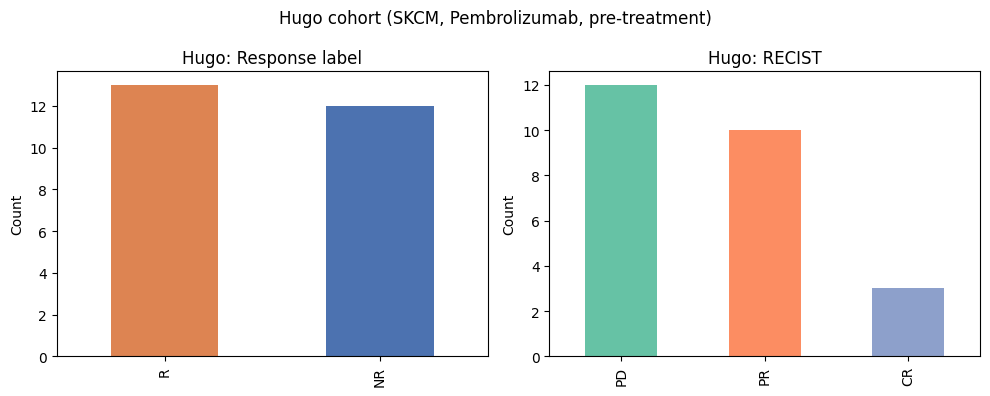

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

hugo_adata_log1p.obs["response_label"].value_counts().plot.bar(
    ax=axes[0], color=["#DD8452", "#4C72B0"]
)
axes[0].set_title("Hugo: Response label")
axes[0].set_xlabel("")
axes[0].set_ylabel("Count")

hugo_adata_log1p.obs["RECIST"].value_counts().plot.bar(
    ax=axes[1], color=sns.color_palette("Set2")
)
axes[1].set_title("Hugo: RECIST")
axes[1].set_xlabel("")
axes[1].set_ylabel("Count")

plt.suptitle("Hugo cohort (SKCM, Pembrolizumab, pre-treatment)", fontsize=12)
plt.tight_layout()
plt.show()

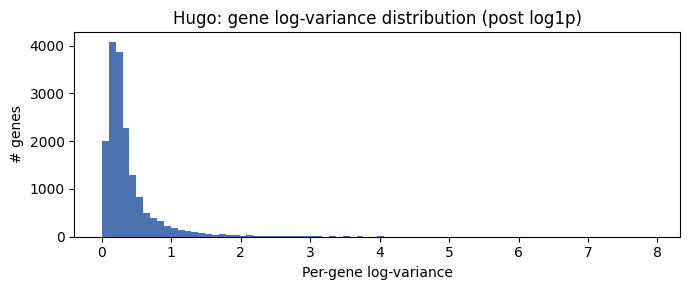

In [60]:
# Per-gene log-variance distribution (log1p version)
plt.figure(figsize=(7, 3))
plt.hist(hugo_adata_log1p.var["log_variance"], bins=80, color="#4C72B0", edgecolor="none")
plt.xlabel("Per-gene log-variance")
plt.ylabel("# genes")
plt.title("Hugo: gene log-variance distribution (post log1p)")
plt.tight_layout()
plt.show()

---
## 2. Riaz cohort (SKCM, anti-PD1, GSE91061)

**Files:**
- `GSE91061_norm_counts.tsv.gz` — TPM matrix, rows = Entrez GeneID, columns = GSM accessions
- `GSE91061_series_matrix.txt.gz` — maps GSM accessions → sample titles (format: `PtN_Pre_<accession>-<digit>`)
- `Human.GRCh38.p13.annot.tsv.gz` — Entrez GeneID → gene symbol + gene type
- `Riaz_clinical.tsv` — clinical/response metadata; Index matches sample titles with trailing `(-\d+)` stripped

In [61]:
# ── Gene annotation (reuse from Hugo — same reference genome) ─────────────────
riaz_annot = load_entrez_to_symbol(HUGO_DIR / "Human.GRCh38.p13.annot.tsv.gz")

# Also copy to Riaz dir for self-containment (symlink alternative)
riaz_annot_by_symbol = riaz_annot.reset_index().set_index("symbol")

In [62]:
# ── Load expression matrix ────────────────────────────────────────────────────
riaz_rna_raw = pd.read_csv(
    RIAZ_DIR / "GSE91061_norm_counts.tsv.gz",
    sep="\t", compression="gzip", index_col=0
)
print(f"Raw expression: {riaz_rna_raw.shape}  (genes x samples)")
riaz_rna_raw.iloc[:4, :4]

Raw expression: (39376, 109)  (genes x samples)


,GSM2420259,GSM2420260,GSM2420261,GSM2420262
GeneID,,,,
100287102,0.1715,0.4562,0.2349,0.13280
653635,11.5300,18.5600,10.9200,9.79800
102466751,8.3340,24.5400,6.9760,3.87200
107985730,0.1756,0.2001,0.0000,0.08156


In [63]:
# ── Map Entrez IDs -> gene symbols ────────────────────────────────────────────
riaz_rna_raw.index = riaz_rna_raw.index.astype(str)
riaz_rna_raw = riaz_rna_raw[riaz_rna_raw.index.isin(riaz_annot.index)]
riaz_rna_raw.index = riaz_rna_raw.index.map(riaz_annot["symbol"])
riaz_rna_raw = riaz_rna_raw[riaz_rna_raw.index.notna()]
riaz_rna_raw = riaz_rna_raw.groupby(level=0).sum()

print(f"After symbol mapping: {riaz_rna_raw.shape}  (genes x samples)")

After symbol mapping: (39374, 109)  (genes x samples)


In [64]:
# ── Transpose to (samples x genes) ───────────────────────────────────────────
riaz_tpm = riaz_rna_raw.T
riaz_tpm.index.name = "gsm_id"

In [65]:
# ── Parse series matrix: GSM -> sample title ──────────────────────────────────
# Riaz sample titles have format: "Pt1_Pre_AD101148-6"
# Clinical Index has format:       "Pt1_Pre_AD101148"   (no trailing -digit)
riaz_gsm_to_title = parse_series_matrix(
    RIAZ_DIR / "GSE91061_series_matrix.txt.gz", compressed=True
)
print(f"Series matrix: {len(riaz_gsm_to_title)} mappings")
list(riaz_gsm_to_title.items())[:5]

Series matrix: 109 mappings


[('GSM2420259', 'Pt1_Pre_AD101148-6'),
 ('GSM2420260', 'Pt1_On_AD174047-6'),
 ('GSM2420261', 'Pt2_Pre_AD101150-6'),
 ('GSM2420262', 'Pt2_On_AD174046-6'),
 ('GSM2420263', 'Pt23_On_AD486568-8')]

In [ ]:
# ── Normalize sample title: strip trailing "-<digits>" suffix ─────────────────
# "Pt1_Pre_AD101148-6" -> "Pt1_Pre_AD101148"  (matches clinical Index)
import re

riaz_gsm_to_clinical_idx = {
    gsm: re.sub(r"-\d+$", "", title)
    for gsm, title in riaz_gsm_to_title.items()
}

print("Sample mapping preview (GSM -> clinical index):")
list(riaz_gsm_to_clinical_idx.items())[:5]

Sample mapping preview (GSM -> clinical index):


[('GSM2420259', 'Pt1_Pre_AD101148'),
 ('GSM2420260', 'Pt1_On_AD174047'),
 ('GSM2420261', 'Pt2_Pre_AD101150'),
 ('GSM2420262', 'Pt2_On_AD174046'),
 ('GSM2420263', 'Pt23_On_AD486568')]

In [67]:
# ── Load clinical data ────────────────────────────────────────────────────────
riaz_clinical = pd.read_csv(RIAZ_DIR / "Riaz_clinical.tsv", sep="\t", index_col=0)
print(f"Clinical: {riaz_clinical.shape}")
print(f"Timing breakdown:\n{riaz_clinical['Timing'].value_counts()}")
riaz_clinical[["Sample_id", "response_label", "RECIST", "Timing", "cancer_type", "ICI", "ICI_target"]].head()

Clinical: (51, 20)
Timing breakdown:
Timing
Pre    51
Name: count, dtype: int64


,Sample_id,response_label,RECIST,Timing,cancer_type,ICI,ICI_target
Index,,,,,,,
Pt1_Pre_AD101148,Pt1_Pre,NR,PD,Pre,SKCM,Nivolumab,PD1
Pt2_Pre_AD101150,Pt2_Pre,NR,SD,Pre,SKCM,Nivolumab,PD1
Pt3_Pre_E9024733,Pt3_Pre,R,PR,Pre,SKCM,Nivolumab,PD1
Pt4_Pre_E9021023,Pt4_Pre,NR,SD,Pre,SKCM,Nivolumab,PD1
Pt5_Pre_E9021022,Pt5_Pre,NR,PD,Pre,SKCM,Nivolumab,PD1


In [68]:
# ── Build obs for Riaz ────────────────────────────────────────────────────────
riaz_tpm["clinical_idx"] = riaz_tpm.index.map(riaz_gsm_to_clinical_idx)
riaz_tpm = riaz_tpm.dropna(subset=["clinical_idx"])

riaz_obs_cols = [
    "Sample_id", "response_label", "RECIST", "Timing", "cancer_type",
    "ICI", "ICI_target", "Gender", "Overall_survival",
    "Alive (Y=1, No=0)", "patient_id", "Prior_CTLA4"
]
riaz_obs_cols = [c for c in riaz_obs_cols if c in riaz_clinical.columns]

riaz_tpm = riaz_tpm.join(
    riaz_clinical[riaz_obs_cols], on="clinical_idx", how="inner"
)

all_obs_cols = ["clinical_idx"] + riaz_obs_cols
riaz_obs_df  = riaz_tpm[all_obs_cols].copy()
riaz_obs_df.index.name = "sample_id"

riaz_expr_df = riaz_tpm.drop(columns=all_obs_cols)

print(f"Riaz samples with clinical data: {len(riaz_obs_df)}")
print(f"Timing breakdown:\n{riaz_obs_df['Timing'].value_counts()}")

Riaz samples with clinical data: 51
Timing breakdown:
Timing
Pre    51
Name: count, dtype: int64


In [69]:
# ── Filter to pre-treatment samples ──────────────────────────────────────────
pre_mask     = riaz_obs_df["Timing"] == "Pre"
riaz_obs_df  = riaz_obs_df[pre_mask]
riaz_expr_df = riaz_expr_df.loc[pre_mask]

print(f"Pre-treatment samples: {len(riaz_obs_df)}")
print(f"Response label distribution:\n{riaz_obs_df['response_label'].value_counts()}")

Pre-treatment samples: 51
Response label distribution:
response_label
NR    41
R     10
Name: count, dtype: int64


In [70]:
# ── Build raw AnnData ─────────────────────────────────────────────────────────
riaz_adata_raw = build_raw_adata(
    tpm_df=riaz_expr_df,
    obs_df=riaz_obs_df,
    annot_df=riaz_annot_by_symbol,
    cohort_name="Riaz"
)
print(riaz_adata_raw)

[Riaz] Raw AnnData: 51 samples x 39374 genes
AnnData object with n_obs × n_vars = 51 × 39374
    obs: 'clinical_idx', 'Sample_id', 'response_label', 'RECIST', 'Timing', 'cancer_type', 'ICI', 'ICI_target', 'Gender', 'Overall_survival', 'Alive (Y=1, No=0)', 'patient_id', 'Prior_CTLA4'
    var: 'gene_symbol', 'gene_type'
    uns: 'cohort'


In [71]:
# Raw h5ad is saved together with processed versions in the next cell

In [72]:
# ── Process & save ───────────────────────────────────────────────────────────
riaz_adata_processed, riaz_adata_log1p = process_adata(riaz_adata_raw)

riaz_rna_dir = RIAZ_DIR / "RNA"
riaz_rna_dir.mkdir(parents=True, exist_ok=True)

riaz_adata_raw.write_h5ad(riaz_rna_dir / "Riaz_bulk_RNA_raw.h5ad")
riaz_adata_processed.write_h5ad(riaz_rna_dir / "Riaz_bulk_RNA_processed.h5ad")
riaz_adata_log1p.write_h5ad(riaz_rna_dir / "Riaz_bulk_RNA_processed_log1p.h5ad")

summarize_cohort(riaz_adata_log1p)

[Riaz] After expression filter (mean TPM >= 0.1): 26142 genes
[Riaz] After protein-coding filter: 17129 genes
[Riaz] Processed: 51 x 17129

 Cohort: Riaz
 Samples : 51
 Genes   : 17129
 obs cols: ['clinical_idx', 'Sample_id', 'response_label', 'RECIST', 'Timing', 'cancer_type', 'ICI', 'ICI_target', 'Gender', 'Overall_survival', 'Alive (Y=1, No=0)', 'patient_id', 'Prior_CTLA4']
 Response:
response_label
NR    41
R     10
 RECIST:
RECIST
PD    25
SD    16
PR     7
CR     3


### Riaz: exploratory visualizations

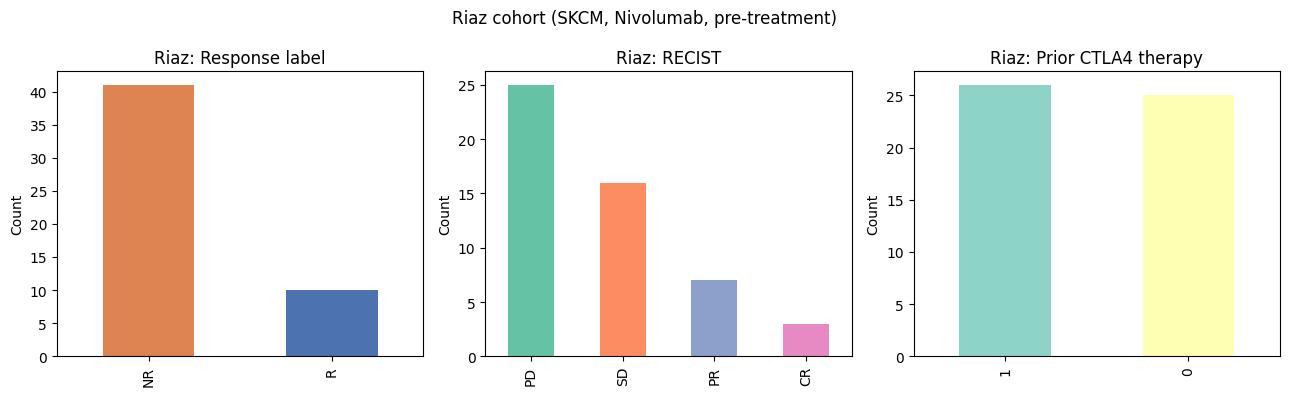

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

riaz_adata_log1p.obs["response_label"].value_counts().plot.bar(
    ax=axes[0], color=["#DD8452", "#4C72B0"]
)
axes[0].set_title("Riaz: Response label")
axes[0].set_xlabel("")
axes[0].set_ylabel("Count")

riaz_adata_log1p.obs["RECIST"].value_counts().plot.bar(
    ax=axes[1], color=sns.color_palette("Set2")
)
axes[1].set_title("Riaz: RECIST")
axes[1].set_xlabel("")
axes[1].set_ylabel("Count")

riaz_adata_log1p.obs["Prior_CTLA4"].value_counts().plot.bar(
    ax=axes[2], color=sns.color_palette("Set3")
)
axes[2].set_title("Riaz: Prior CTLA4 therapy")
axes[2].set_xlabel("")
axes[2].set_ylabel("Count")

plt.suptitle("Riaz cohort (SKCM, Nivolumab, pre-treatment)", fontsize=12)
plt.tight_layout()
plt.show()

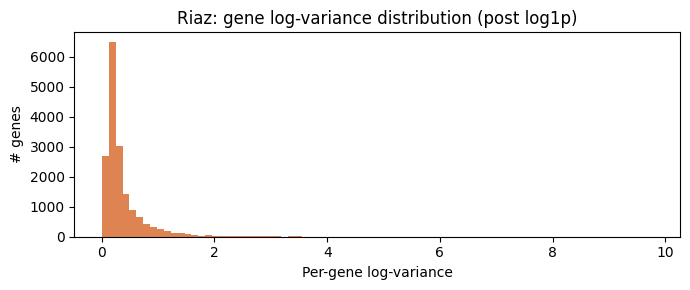

In [74]:
# Per-gene log-variance distribution (log1p version)
plt.figure(figsize=(7, 3))
plt.hist(riaz_adata_log1p.var["log_variance"], bins=80, color="#DD8452", edgecolor="none")
plt.xlabel("Per-gene log-variance")
plt.ylabel("# genes")
plt.title("Riaz: gene log-variance distribution (post log1p)")
plt.tight_layout()
plt.show()

---
## 3. Rose cohort (BLCA, multiple ICI agents, GSE176307)

**Files:**
- `GSE176307_salmon_tpm_gene.matrix.tsv.gz` — TPM matrix, rows = gene symbols, columns = `RS-XXXXXXX` sample IDs
- `Rose_clinical.tsv` — clinical/response metadata; `Sample_id` column matches expression column headers

No Entrez-to-symbol conversion is needed as gene symbols are already used.
Gene type annotation uses the NCBI reference from Hugo (same genome build).

In [75]:
# ── Load expression matrix ────────────────────────────────────────────────────
# The Rose matrix is transposed vs Hugo/Riaz: rows = gene symbols, cols = sample IDs
rose_rna_raw = pd.read_csv(
    ROSE_DIR / "GSE176307_salmon_tpm_gene.matrix.tsv.gz",
    sep="\t", compression="gzip", index_col=0
)

# Ensure gene name column is correctly named
rose_rna_raw.index.name = "gene_symbol"

print(f"Raw expression: {rose_rna_raw.shape}  (genes x samples)")
rose_rna_raw.iloc[:4, :4]

Raw expression: (58387, 92)  (genes x samples)


,RS-03238953,RS-03238954,RS-03238955,RS-03238956
gene_symbol,,,,
5S_rRNA,40.473330,4.791860,7.564440,23.424800
5_8S_rRNA,0.735559,0.000000,0.000000,0.000000
7SK,0.382188,0.280699,0.241591,2.978596
A1BG,7.538390,2.731250,4.731560,11.375700


In [76]:
# ── Collapse duplicate gene symbols (sum) and transpose ───────────────────────
rose_rna_raw = rose_rna_raw.groupby(level=0).sum()
rose_tpm = rose_rna_raw.T          # rows = RS-XXXXXXX sample IDs, cols = gene symbols
rose_tpm.index.name = "sample_id"

print(f"Transposed shape (samples x genes): {rose_tpm.shape}")

Transposed shape (samples x genes): (92, 58387)


In [77]:
# ── Load clinical data ────────────────────────────────────────────────────────
rose_clinical = pd.read_csv(ROSE_DIR / "Rose_clinical.tsv", sep="\t", index_col=0)
print(f"Clinical: {rose_clinical.shape}")
print(f"Timing breakdown:\n{rose_clinical['Timing'].value_counts()}")
rose_clinical[["Sample_id", "response_label", "RECIST", "Timing", "cancer_type", "ICI", "ICI_target"]].head()

Clinical: (89, 36)
Timing breakdown:
Timing
Pre    89
Name: count, dtype: int64


,Sample_id,response_label,RECIST,Timing,cancer_type,ICI,ICI_target
Index,,,,,,,
UCC_Rose_RS.03238999,RS-03238999,NR,PD,Pre,BLCA,Durvalumab,PD-L1
UCC_Rose_RS.03239000,RS-03239000,NR,PD,Pre,BLCA,Pembrolizumab,PD1
UCC_Rose_RS.03239001,RS-03239001,NR,PD,Pre,BLCA,Atezolizumab,PD-L1
UCC_Rose_RS.03239002,RS-03239002,R,PR,Pre,BLCA,Atezolizumab,PD-L1
UCC_Rose_RS.03239003,RS-03239003,NR,PD,Pre,BLCA,Nivolumab,PD1


In [78]:
# ── Join expression + clinical ────────────────────────────────────────────────
# Clinical 'Sample_id' matches the expression matrix index directly
rose_clinical_indexed = rose_clinical.set_index("Sample_id")

rose_obs_cols = [
    "response_label", "RECIST", "Timing", "cancer_type",
    "ICI", "ICI_target", "gender", "age", "TMB",
    "os (days)", "alive", "pfs", "progressed", "patient_id",
    "histology", "smoking status"
]
rose_obs_cols = [c for c in rose_obs_cols if c in rose_clinical_indexed.columns]

common_samples = rose_tpm.index.intersection(rose_clinical_indexed.index)
rose_expr_df   = rose_tpm.loc[common_samples]
rose_obs_df    = rose_clinical_indexed.loc[common_samples, rose_obs_cols]

print(f"Samples in both expression and clinical: {len(common_samples)}")
print(f"Timing breakdown:\n{rose_obs_df['Timing'].value_counts()}")

Samples in both expression and clinical: 89
Timing breakdown:
Timing
Pre    89
Name: count, dtype: int64


In [79]:
# ── Filter to pre-treatment samples ──────────────────────────────────────────
pre_mask     = rose_obs_df["Timing"] == "Pre"
rose_obs_df  = rose_obs_df[pre_mask]
rose_expr_df = rose_expr_df.loc[pre_mask]

print(f"Pre-treatment samples: {len(rose_obs_df)}")
print(f"Response label distribution:\n{rose_obs_df['response_label'].value_counts()}")

Pre-treatment samples: 89
Response label distribution:
response_label
NR    73
R     16
Name: count, dtype: int64


In [80]:
# ── Annotate gene types using the Hugo annotation table ───────────────────────
# Rose uses gene symbols; look them up in the symbol-indexed annotation
rose_annot_by_symbol = hugo_annot.reset_index().set_index("symbol")

# ── Build raw AnnData ─────────────────────────────────────────────────────────
rose_adata_raw = build_raw_adata(
    tpm_df=rose_expr_df,
    obs_df=rose_obs_df,
    annot_df=rose_annot_by_symbol,
    cohort_name="Rose"
)
print(rose_adata_raw)

[Rose] Raw AnnData: 89 samples x 58387 genes
AnnData object with n_obs × n_vars = 89 × 58387
    obs: 'response_label', 'RECIST', 'Timing', 'cancer_type', 'ICI', 'ICI_target', 'gender', 'age', 'TMB', 'os (days)', 'alive', 'pfs', 'progressed', 'patient_id', 'histology', 'smoking status'
    var: 'gene_symbol', 'gene_type'
    uns: 'cohort'


In [81]:
# Raw h5ad is saved together with processed versions in the next cell

In [82]:
# ── Process & save ───────────────────────────────────────────────────────────
rose_adata_processed, rose_adata_log1p = process_adata(rose_adata_raw)

rose_rna_dir = ROSE_DIR / "RNA"
rose_rna_dir.mkdir(parents=True, exist_ok=True)

rose_adata_raw.write_h5ad(rose_rna_dir / "Rose_bulk_RNA_raw.h5ad")
rose_adata_processed.write_h5ad(rose_rna_dir / "Rose_bulk_RNA_processed.h5ad")
rose_adata_log1p.write_h5ad(rose_rna_dir / "Rose_bulk_RNA_processed_log1p.h5ad")

summarize_cohort(rose_adata_log1p)

[Rose] After expression filter (mean TPM >= 0.1): 29111 genes
[Rose] After protein-coding filter: 16934 genes
[Rose] Processed: 89 x 16934

 Cohort: Rose
 Samples : 89
 Genes   : 16934
 obs cols: ['response_label', 'RECIST', 'Timing', 'cancer_type', 'ICI', 'ICI_target', 'gender', 'age', 'TMB', 'os (days)', 'alive', 'pfs', 'progressed', 'patient_id', 'histology', 'smoking status']
 Response:
response_label
NR    73
R     16
 RECIST:
RECIST
PD    69
PR     9
CR     7
SD     4


### Rose: exploratory visualizations

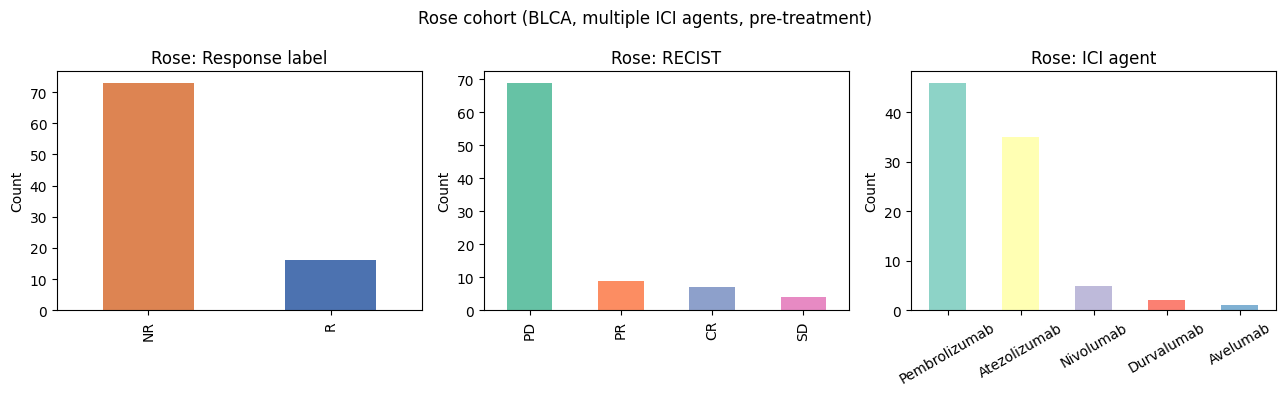

In [83]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

rose_adata_log1p.obs["response_label"].value_counts().plot.bar(
    ax=axes[0], color=["#DD8452", "#4C72B0"]
)
axes[0].set_title("Rose: Response label")
axes[0].set_xlabel("")
axes[0].set_ylabel("Count")

rose_adata_log1p.obs["RECIST"].value_counts().plot.bar(
    ax=axes[1], color=sns.color_palette("Set2")
)
axes[1].set_title("Rose: RECIST")
axes[1].set_xlabel("")
axes[1].set_ylabel("Count")

rose_adata_log1p.obs["ICI"].value_counts().plot.bar(
    ax=axes[2], color=sns.color_palette("Set3")
)
axes[2].set_title("Rose: ICI agent")
axes[2].set_xlabel("")
axes[2].set_ylabel("Count")
axes[2].tick_params(axis="x", rotation=30)

plt.suptitle("Rose cohort (BLCA, multiple ICI agents, pre-treatment)", fontsize=12)
plt.tight_layout()
plt.show()

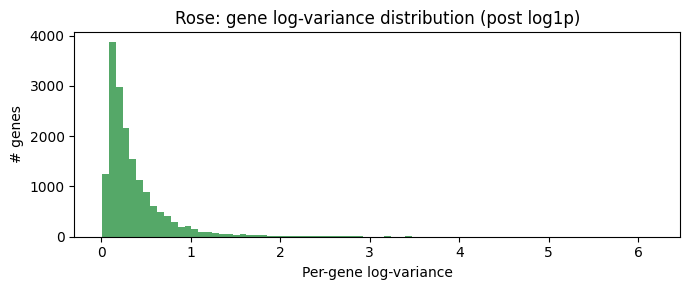

In [84]:
# Per-gene log-variance distribution (log1p version)
plt.figure(figsize=(7, 3))
plt.hist(rose_adata_log1p.var["log_variance"], bins=80, color="#55A868", edgecolor="none")
plt.xlabel("Per-gene log-variance")
plt.ylabel("# genes")
plt.title("Rose: gene log-variance distribution (post log1p)")
plt.tight_layout()
plt.show()

---
## 4. Cross-cohort summary

In [85]:
cohorts = {
    "Hugo":  hugo_adata_log1p,
    "Riaz":  riaz_adata_log1p,
    "Rose":  rose_adata_log1p,
}

summary_rows = []
for name, adata in cohorts.items():
    obs = adata.obs
    n_R  = (obs["response_label"] == "R").sum()  if "response_label" in obs.columns else None
    n_NR = (obs["response_label"] == "NR").sum() if "response_label" in obs.columns else None
    summary_rows.append({
        "Cohort":       name,
        "Cancer type":  obs["cancer_type"].iloc[0] if "cancer_type" in obs.columns else "?",
        "ICI target":   obs["ICI_target"].unique().tolist() if "ICI_target" in obs.columns else "?",
        "N samples":    adata.n_obs,
        "N genes":      adata.n_vars,
        "Responders":   n_R,
        "Non-resp.":    n_NR,
    })

summary_df = pd.DataFrame(summary_rows).set_index("Cohort")
display(summary_df)

,Cancer type,ICI target,N samples,N genes,Responders,Non-resp.
Cohort,,,,,,
Hugo,SKCM,[PD1],25,16857,13,12
Riaz,SKCM,[PD1],51,17129,10,41
Rose,BLCA,"[PD-L1, PD1]",89,16934,16,73


In [90]:
# ── Shared protein-coding genes across all three cohorts ─────────────────────
hugo_genes = set(hugo_adata_log1p.var_names)
riaz_genes = set(riaz_adata_log1p.var_names)
rose_genes = set(rose_adata_log1p.var_names)

shared_hugo_riaz = hugo_genes & riaz_genes
shared_all       = hugo_genes & riaz_genes & rose_genes

print(f"Hugo genes:          {len(hugo_genes)}")
print(f"Riaz genes:          {len(riaz_genes)}")
print(f"Rose genes:          {len(rose_genes)}")
print(f"Hugo and Riaz and Rose:  {len(shared_all)}")

Hugo genes:          16857
Riaz genes:          17129
Rose genes:          16934
Hugo and Riaz and Rose:  15373


In [88]:
print("Output files written:")
for name, d in [("Hugo", HUGO_DIR), ("Riaz", RIAZ_DIR), ("Rose", ROSE_DIR)]:
    rna_dir = d / "RNA"
    for suffix in ["raw", "processed", "processed_log1p"]:
        p = rna_dir / f"{name}_bulk_RNA_{suffix}.h5ad"
        size_mb = p.stat().st_size / 1e6 if p.exists() else float("nan")
        status = f"{size_mb:.1f} MB" if p.exists() else "MISSING"
        print(f"  {str(p.relative_to(REPO_DIR))}  [{status}]")

Output files written:
  data/immunotherapy_cohorts/Hugo/RNA/Hugo_bulk_RNA_raw.h5ad  [6.8 MB]
  data/immunotherapy_cohorts/Hugo/RNA/Hugo_bulk_RNA_processed.h5ad  [2.8 MB]
  data/immunotherapy_cohorts/Hugo/RNA/Hugo_bulk_RNA_processed_log1p.h5ad  [2.9 MB]
  data/immunotherapy_cohorts/Riaz/RNA/Riaz_bulk_RNA_raw.h5ad  [10.9 MB]
  data/immunotherapy_cohorts/Riaz/RNA/Riaz_bulk_RNA_processed.h5ad  [4.7 MB]
  data/immunotherapy_cohorts/Riaz/RNA/Riaz_bulk_RNA_processed_log1p.h5ad  [4.8 MB]
  data/immunotherapy_cohorts/Rose/RNA/Rose_bulk_RNA_raw.h5ad  [25.1 MB]
  data/immunotherapy_cohorts/Rose/RNA/Rose_bulk_RNA_processed.h5ad  [7.2 MB]
  data/immunotherapy_cohorts/Rose/RNA/Rose_bulk_RNA_processed_log1p.h5ad  [7.3 MB]


### IMMotion150 and IMVigor210

In [1]:
from pathlib import Path

cohorts = {
    "IMVigor210": Path("/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/immunotherapy_cohorts/IMVigor210/RNA/paired"),
    "IMMotion150": Path("/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/immunotherapy_cohorts/IMMotion150/RNA/paired"),
}

for cohort, paired_dir in cohorts.items():
    sample_dirs = [d for d in paired_dir.iterdir() if d.is_dir()]
    complete, incomplete = [], []
    for d in sample_dirs:
        fqs = [f for f in d.glob("*.fastq.gz") if not f.name.endswith(".md5")]
        if len(fqs) == 2:
            complete.append(d.name)
        else:
            incomplete.append((d.name, len(fqs)))

    print(f"=== {cohort} ===")
    print(f"  Total samples:    {len(sample_dirs)}")
    print(f"  Complete (2 fqs): {len(complete)}")
    print(f"  Incomplete:       {len(incomplete)}")
    if incomplete:
        for name, count in incomplete:
            print(f"    {name}: {count} file(s)")
    print()

=== IMVigor210 ===
  Total samples:    348
  Complete (2 fqs): 348
  Incomplete:       0

=== IMMotion150 ===
  Total samples:    263
  Complete (2 fqs): 263
  Incomplete:       0



In [2]:
# Verify unique file names per thing
for cohort, paired_dir in cohorts.items():
    sample_dirs = [d for d in paired_dir.iterdir() if d.is_dir()]
    all_fqs = []
    for d in sample_dirs:
        fqs = [f.name for f in d.glob("*.fastq.gz") if not f.name.endswith(".md5")]
        all_fqs.extend(fqs)

    unique_fqs = set(all_fqs)
    if len(all_fqs) != len(unique_fqs):
        print(f"Warning: duplicate file names found in {cohort}!")
    else:
        print(f"All file names are unique in {cohort}.")

All file names are unique in IMVigor210.
All file names are unique in IMMotion150.


### Get metadata for COMPASS

In [1]:
import pickle, json
import numpy as np
import pandas as pd
import anndata as ad
from pathlib import Path

REPO = Path("/data/rbg/users/ashyamal/RNA-FM-benchmarking")

H5AD_PATHS = {
    "Riaz":        REPO / "data/immunotherapy_cohorts/Riaz/RNA/Riaz_bulk_RNA_processed.h5ad",
    "Hugo":        REPO / "data/immunotherapy_cohorts/Hugo/RNA/Hugo_bulk_RNA_processed.h5ad",
    "Rose":        REPO / "data/immunotherapy_cohorts/Rose/RNA/Rose_bulk_RNA_processed.h5ad",
    "IMMotion150": REPO / "data/immunotherapy_cohorts/IMMotion150/RNA/IMMotion150_bulk_RNA_processed.h5ad",
    "IMVigor210":  REPO / "data/immunotherapy_cohorts/IMVigor210/RNA/IMVigor210_bulk_RNA_processed.h5ad",
}

with open(REPO / "data/RNA_embeddings/ICI/ICI_all_processed.pkl", "rb") as f:
    data = pickle.load(f)
pkl_ids = set(data.keys())

tpm_frames = []
for cohort, path in H5AD_PATHS.items():
    adata = ad.read_h5ad(path)
    expr = pd.DataFrame(
        adata.X if not hasattr(adata.X, "toarray") else adata.X.toarray(),
        index=adata.obs_names,
        columns=adata.var_names,
    )
    # Mirror get_sample_ids(): prefer patient_id, fall back to obs_names
    if "patient_id" in adata.obs.columns:
        id_map = dict(zip(adata.obs_names, adata.obs["patient_id"].astype(str)))
    else:
        id_map = dict(zip(adata.obs_names, adata.obs_names))

    expr.index = [id_map[i] for i in expr.index]
    matched = expr[expr.index.isin(pkl_ids)]
    print(f"{cohort}: {len(matched)}/{len(expr)} samples matched  (sample IDs e.g. {list(matched.index[:3])})")
    tpm_frames.append(matched)

tpm_all = pd.concat(tpm_frames)
print(f"\nTotal: {len(tpm_all)} samples, {tpm_all.shape[1]} genes")

out_path = REPO / "data/RNA_embeddings/ICI/ICI_tpm.parquet"
tpm_all.to_parquet(out_path)
print(f"Saved → {out_path}")

meta = {
    sid: {
        "response":    int(rec["response"]),
        "cancer_type": str(rec.get("cancer_type", "")),
        "cohort":      str(rec.get("cohort", "")),
    }
    for sid, rec in data.items()
}
with open(REPO / "data/RNA_embeddings/ICI/ICI_meta.json", "w") as f:
    json.dump(meta, f)
print(f"Saved ICI_meta.json with {len(meta)} samples")

Riaz: 51/51 samples matched  (sample IDs e.g. ['Pt1', 'Pt2', 'Pt23'])
Hugo: 25/25 samples matched  (sample IDs e.g. ['GSM2069823', 'GSM2069824', 'GSM2069825'])
Rose: 89/89 samples matched  (sample IDs e.g. ['BACI170', 'BACI191', 'BACI192'])
IMMotion150: 247/247 samples matched  (sample IDs e.g. ['007603faf7a3', '0098b8010fb0', '014307e64a29'])
IMVigor210: 298/298 samples matched  (sample IDs e.g. ['SAM0257bbbbd388', 'SAM025b45c27e05', 'SAM032c642382a7'])

Total: 710 samples, 19156 genes
Saved → /data/rbg/users/ashyamal/RNA-FM-benchmarking/data/RNA_embeddings/ICI/ICI_tpm.parquet
Saved ICI_meta.json with 710 samples
